# BEPAD: get the data

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ecastillot/BEPAD/blob/main/notebooks/01_get_the_data.ipynb)

Load a few windows, look at one, and choose windows by their metadata. About 2 minutes.
Documentation: [Get the data](https://bepad.readthedocs.io/en/latest/get_data.html) · [Understand a window](https://bepad.readthedocs.io/en/latest/window.html).

In [ ]:
%pip install -q "bepad>=0.1.2"
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"     # quieter downloads

In [ ]:
import bepad
bepad.__version__

'0.1.2'

## 1. Load a few windows

[`bepad.load`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.load) downloads only what you ask for (here 20 test windows of the Texas and Colombia
networks) and caches it, so the next call is instant. `max_windows` is a fixed random sample per
network.

In [ ]:
test = bepad.load("test", networks=["tx", "CM"], max_windows=20)
test

<bepad.Split 40 windows, 24325 picks, 2 networks, labels=True>

One **window** ([`WindowData`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.data.WindowData)) is one association problem:
its `picks`, the `stations` operating in it, and the true earthquakes (`events`). The label of every
pick is `event_idx`: its earthquake (0, 1, 2 …) or **−1 for noise**. Columns:
[File format](https://bepad.readthedocs.io/en/latest/reference/format.html).

In [ ]:
w = test[0]
print(w.window_id)
w.picks.head()

CM.test.ev-sparse__noise-none.00053


,window_id,pick_idx,station,phase,t_rel_s,time,event_idx,pick_type,real,prob,sigma_s,in_scorable_event,src_event_id,src_pick_id
0,CM.test.ev-sparse__noise-none.00053,0,CM.VMM09,P,75.521366,2020-03-11 08:07:55.670402128,0,real,1,0.715026,0.553493,True,smi:local/SGC2020adzbnr,smi:local/Pick/CM.VMM09.00.HHZ/20200103T034900...
1,CM.test.ev-sparse__noise-none.00053,1,CM.PDSC,P,75.896992,2020-03-11 08:07:56.046028128,0,real,1,0.709541,0.568423,True,smi:local/SGC2020adzbnr,smi:local/Pick/CM.PDSC.10.HNZ/20200103T034901....
2,CM.test.ev-sparse__noise-none.00053,2,CM.EZNC,P,77.285306,2020-03-11 08:07:57.434342128,0,real,1,0.702318,0.589066,True,smi:local/SGC2020adzbnr,smi:local/Pick/CM.EZNC.00.HHZ/20200103T034902....
3,CM.test.ev-sparse__noise-none.00053,3,CM.BAR2,P,77.570782,2020-03-11 08:07:57.719818128,0,real,1,0.702167,0.589509,True,smi:local/SGC2020adzbnr,smi:local/Pick/CM.BAR2.00.HHZ/20200103T034902....
4,CM.test.ev-sparse__noise-none.00053,4,CM.VMM07,P,77.600832,2020-03-11 08:07:57.749868128,0,real,1,0.703541,0.585486,True,smi:local/SGC2020adzbnr,smi:local/Pick/CM.VMM07.00.HHZ/20200103T034902...


In [ ]:
w.picks.pick_type.value_counts()      # real, generated (plausible extra arrivals) and noise picks

pick_type
real         26
generated     1
Name: count, dtype: int64

In [ ]:
w.events[["event_idx", "origin_time", "latitude", "longitude", "depth", "magnitude"]]

,event_idx,origin_time,latitude,longitude,depth,magnitude
0,0,2020-03-11 08:07:40.022666128,7.09,-73.41,114700.0,1.54
1,1,2020-03-11 08:09:36.000000000,6.82,-73.17,143610.0,1.90


## 2. Look at a window

[`plot_window_anatomy`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.plots.plot_window_anatomy): (a) where the earthquakes and
stations are, (b) every pick at its distance from its earthquake, (c) picks by type. The
associator's job: find which picks belong together.

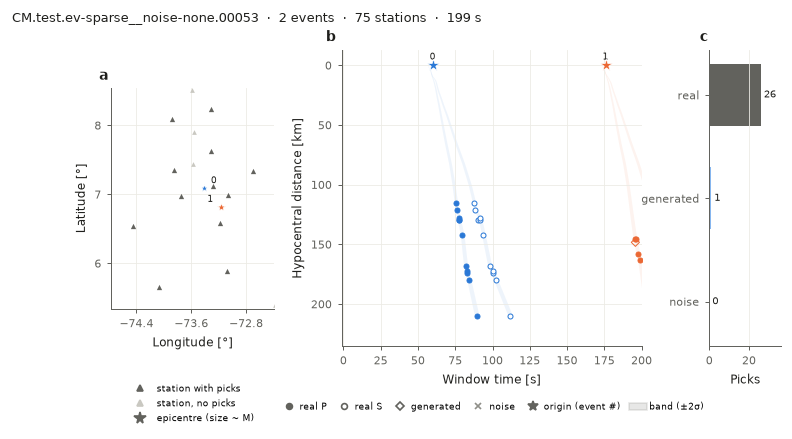

In [ ]:
from bepad.plots import plot_window_anatomy

plot_window_anatomy(w, model=test.release.label_model);

## 3. Difficulty: scenarios

Windows come in 23 scenarios: more earthquakes at once (left to right) and more noise (top to
bottom), plus earthquakes outside the network. Each panel shows its `window_id`.
[`plot_scenario_grid`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.plots.plot_scenario_grid) · [Scenarios](https://bepad.readthedocs.io/en/latest/scenarios.html).

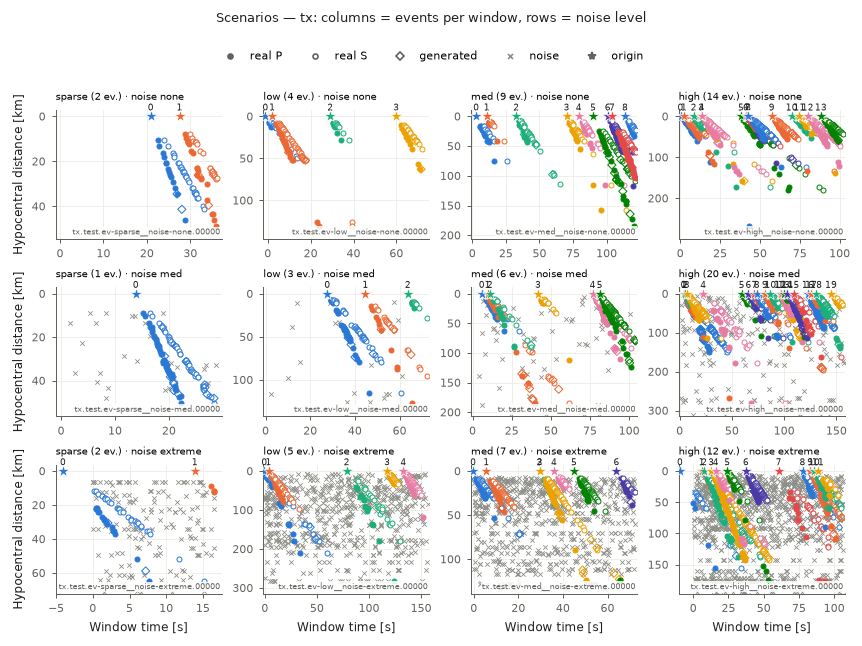

In [ ]:
from bepad.plots import plot_scenario_grid

grid = [f"tx.test.ev-{ev}__noise-{noise}.00000" for ev in ("sparse", "low", "med", "high")
        for noise in ("none", "med", "extreme")]
plot_scenario_grid(bepad.load("test", window_ids=grid), "tx");

## 4. Choose windows

Every window has a row of metadata. Read it with [`Release.table`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.data.Release.table)
(small, no picks), filter it, then load only the windows you chose with `window_ids`. All columns:
[windows table](https://bepad.readthedocs.io/en/latest/reference/format.html#windows).

In [ ]:
meta = test.release.table("test", "windows", networks=["tx", "CM"])
meta[["window_id", "scenario", "n_events", "max_concurrent_events", "noise_ratio", "gap_max_deg", "mag_max"]].head()

,window_id,scenario,n_events,max_concurrent_events,noise_ratio,gap_max_deg,mag_max
0,CM.test.ev-sparse__noise-none.00000,ev-sparse__noise-none,2,1,0.0,125.973040,1.79
1,CM.test.ev-sparse__noise-none.00001,ev-sparse__noise-none,1,1,0.0,247.855119,1.69
2,CM.test.ev-sparse__noise-none.00002,ev-sparse__noise-none,1,1,0.0,273.024071,2.62
3,CM.test.ev-sparse__noise-none.00003,ev-sparse__noise-none,1,1,0.0,76.605065,1.40
4,CM.test.ev-sparse__noise-none.00004,ev-sparse__noise-none,2,1,0.0,171.508653,2.09


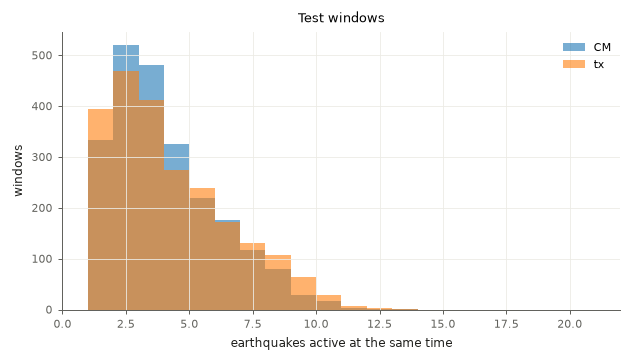

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3))
for net, g in meta.groupby("network"):
    ax.hist(g.max_concurrent_events, bins=range(1, 22), alpha=0.6, label=net)
ax.set(xlabel="earthquakes active at the same time", ylabel="windows", title="Test windows")
ax.legend();

145 crowded, noisy windows


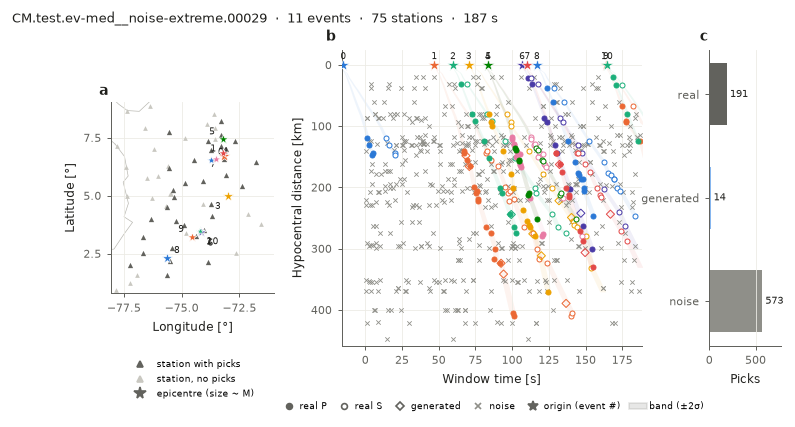

In [ ]:
crowded = meta[(meta.max_concurrent_events >= 8) & (meta.noise_ratio_target >= 1)]
hard = bepad.load("test", window_ids=crowded.window_id)
print(len(crowded), "crowded, noisy windows")
plot_window_anatomy(hard[0], model=hard.release.label_model);

## Next

* [Benchmark your associator](https://colab.research.google.com/github/ecastillot/BEPAD/blob/main/notebooks/02_benchmark.ipynb)
  (notebook) · [Train a model](https://colab.research.google.com/github/ecastillot/BEPAD/blob/main/notebooks/03_train.ipynb) (notebook)
* More filters (by station) and loading without the package: [Get the data](https://bepad.readthedocs.io/en/latest/get_data.html)
* How much data, and statistics: [Dataset statistics](https://bepad.readthedocs.io/en/latest/reference/statistics.html)